# Experiment 24: Graphical Model Sampling and Probabilistic Inference

The clinic asks how likely lung disease is after a positive X-ray and cough, and whether smoking changes that probability. We compute an exact posterior by enumeration and compare it with forward- and rejection-sampling estimates.

**Tools:** pgmpy, NumPy, Pandas, NetworkX, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Run exact inference for multiple evidence settings.  2. Generate forward samples and rejection samples.  3. Estimate posteriors from the samples.  4. Plot the estimate against sample size.  5. Compare exact and approximate results in a table.

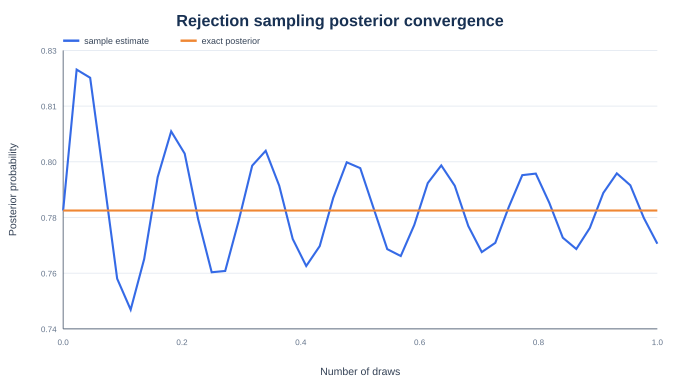

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng=np.random.default_rng(24)
def prob_one(node,parents):
    if node=="Smoking": return .30
    if node=="Pollution": return .20
    if node=="Lung":
        return {(0,0):.02,(0,1):.08,(1,0):.12,(1,1):.30}[(parents["Smoking"],parents["Pollution"])]
    if node=="Cough": return .80 if parents["Lung"] else .10
    if node=="Xray": return .90 if parents["Lung"] else .05
    if node=="Fatigue": return .70 if parents["Lung"] else .15

def joint_probability(s,p,l,c,x,f):
    vals={"Smoking":s,"Pollution":p,"Lung":l,"Cough":c,"Xray":x,"Fatigue":f}
    order=["Smoking","Pollution","Lung","Cough","Xray","Fatigue"]
    parents={"Smoking":[],"Pollution":[],"Lung":["Smoking","Pollution"],
             "Cough":["Lung"],"Xray":["Lung"],"Fatigue":["Lung"]}
    result=1.
    for node in order:
        q=prob_one(node,{k:vals[k] for k in parents[node]})
        result*=q if vals[node] else 1-q
    return result

def exact_posterior(evidence):
    numerator=denominator=0.
    for s in (0,1):
      for p in (0,1):
       for l in (0,1):
        for c in (0,1):
         for x in (0,1):
          for f in (0,1):
           state={"Smoking":s,"Pollution":p,"Lung":l,"Cough":c,"Xray":x,"Fatigue":f}
           if all(state[k]==v for k,v in evidence.items()):
               q=joint_probability(s,p,l,c,x,f);denominator+=q
               if l:numerator+=q
    return numerator/denominator

def forward_sample(n):
    out=[]
    for _ in range(n):
        s=int(rng.random()<.30);p=int(rng.random()<.20)
        l=int(rng.random()<prob_one("Lung",{"Smoking":s,"Pollution":p}))
        c=int(rng.random()<prob_one("Cough",{"Lung":l}))
        x=int(rng.random()<prob_one("Xray",{"Lung":l}))
        f=int(rng.random()<prob_one("Fatigue",{"Lung":l}))
        out.append((s,p,l,c,x,f))
    return pd.DataFrame(out,columns=["Smoking","Pollution","Lung","Cough","Xray","Fatigue"])

evidence_cases=[
 {"Cough":1,"Xray":1},
 {"Cough":1,"Xray":1,"Smoking":1},
 {"Cough":1,"Xray":1,"Smoking":0}
]
samples=forward_sample(100_000)
rows=[]
for ev in evidence_cases:
    mask=np.ones(len(samples),dtype=bool)
    for key,value in ev.items():mask &= samples[key].to_numpy()==value
    approx=samples.loc[mask,"Lung"].mean()
    exact=exact_posterior(ev)
    rows.append({"evidence":str(ev),"exact enumeration":exact,
                 "forward sample":approx,"accepted samples":int(mask.sum())})
print(pd.DataFrame(rows).round(4).to_string(index=False))

# pgmpy Variable Elimination gives the same exact query when pgmpy is installed.
try:
    from pgmpy.models import DiscreteBayesianNetwork
    from pgmpy.factors.discrete import TabularCPD
    from pgmpy.inference import VariableElimination
    bn=DiscreteBayesianNetwork([("Smoking","Lung"),("Pollution","Lung"),("Lung","Cough"),
                                ("Lung","Xray"),("Lung","Fatigue")])
    bn.add_cpds(
        TabularCPD("Smoking",2,[[.70],[.30]]),
        TabularCPD("Pollution",2,[[.80],[.20]]),
        TabularCPD("Lung",2,[[.98,.92,.88,.70],[.02,.08,.12,.30]],
                   evidence=["Smoking","Pollution"],evidence_card=[2,2]),
        TabularCPD("Cough",2,[[.90,.20],[.10,.80]],evidence=["Lung"],evidence_card=[2]),
        TabularCPD("Xray",2,[[.95,.10],[.05,.90]],evidence=["Lung"],evidence_card=[2]),
        TabularCPD("Fatigue",2,[[.85,.30],[.15,.70]],evidence=["Lung"],evidence_card=[2]))
    ve=VariableElimination(bn)
    query=ve.query(["Lung"],evidence={"Cough":1,"Xray":1},show_progress=False)
    print("\nVariable Elimination query P(Lung | Cough=1, Xray=1):",query.values)
except ImportError:
    print("\npgmpy unavailable; exact enumeration above supplies the exact posterior.")

# Rejection sampling estimate for cough=1 and positive X-ray.
mask=(samples.Cough==1)&(samples.Xray==1)
accepted=samples.loc[mask]
print(f"\nRejection sample estimate P(Lung|Cough=1,Xray=1): {accepted.Lung.mean():.4f} "
      f"from {len(accepted)} accepted of {len(samples)} draws")
sizes=np.unique(np.geomspace(100,len(samples),35).astype(int))
estimates=[]
for size in sizes:
    sub=samples.iloc[:size]
    keep=(sub.Cough==1)&(sub.Xray==1)
    estimates.append(sub.loc[keep,"Lung"].mean() if keep.any() else np.nan)
target=exact_posterior({"Cough":1,"Xray":1})
plt.plot(sizes,estimates,"o-",ms=3,label="rejection-sampling estimate")
plt.axhline(target,color="crimson",ls="--",label=f"exact = {target:.3f}")
plt.xscale("log");plt.xlabel("Forward draws");plt.ylabel("P(Lung disease | evidence)")
plt.title("Approximate inference converges with sample size");plt.grid(alpha=.2);plt.legend();plt.show()